# Notebook 01: Dữ liệu & Data Augmentation tái lập (ESP32-CAM OV2640)
`src/data_augmentation.py` sinh tập đánh giá đa kịch bản có Ground Truth (seed cố định, manifest đầy đủ tại `data/augmented/manifest.csv`):
1. **haze_pink**: $I = c\,J + (1-c)A$ + bão hoà lệch hồng (R/B tăng, G giảm) vùng sáng.
2. **low_light**: giảm phơi sáng trong miền tuyến tính, nhiễu Poisson–Gaussian CMOS, color cast, nâng black level, JPEG.
3. **backlit_uneven**: trường chiếu sáng mượt ngẫu nhiên (bóng râm / ngược sáng).
4. **motion_jpeg**: motion blur góc ngẫu nhiên + defocus + JPEG 8×8 Q∈[25,60].
5. **geometric**: roll ±7°, crop/scale, flip (áp dụng đồng thời cho GT và ảnh suy giảm).

In [1]:
import os, sys, cv2, pandas as pd
ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))  # notebook đặt trong notebooks/
sys.path.insert(0, ROOT)
from src.data_augmentation import generate_augmented_benchmark
df = generate_augmented_benchmark(seed=2026)
print(df.groupby("scenario").size())
df.head()

scenario
backlit_uneven    30
geometric         32
haze_pink         30
low_light         30
motion_jpeg       30


scenario,filename,gt,seed,index,params
haze_pink,haze_pink/haze_pink_001.jpg,data/synthetic_gt/uav_gt_001.jpg,2026,0,"{""contrast_keep"": 0.763, ""airlight"": 203.0, ""hl_thresh"": 162.1, ""r_boost"": 45.9, ""b_boost"": 32.6, ""g_drop"": 23.0, ""noise_sigma"": 1.76, ""jpeg_quality"": 81}"
low_light,low_light/low_light_001.jpg,data/synthetic_gt/uav_gt_001.jpg,2026,0,"{""exposure"": 0.063, ""photon_full_scale"": 477.0, ""read_sigma"": 0.0045, ""cast_b"": 0.952, ""cast_g"": 0.977, ""cast_r"": 0.803, ""black_level"": 0.065, ""jpeg_quality"": 91}"
backlit_uneven,backlit_uneven/backlit_uneven_001.jpg,data/synthetic_gt/uav_gt_001.jpg,2026,0,"{""shadow_floor"": 0.233, ""highlight_gain"": 1.19, ""read_sigma"": 0.0092, ""jpeg_quality"": 67}"
motion_jpeg,motion_jpeg/motion_jpeg_001.jpg,data/synthetic_gt/uav_gt_001.jpg,2026,0,"{""motion_len"": 15, ""motion_angle"": 101.3, ""defocus_radius"": 1.09, ""noise_sigma"": 2.18, ""jpeg_quality"": 29}"
haze_pink,haze_pink/haze_pink_002.jpg,data/synthetic_gt/uav_gt_002.jpg,2026,1,"{""contrast_keep"": 0.557, ""airlight"": 196.6, ""hl_thresh"": 166.2, ""r_boost"": 38.0, ""b_boost"": 39.6, ""g_drop"": 41.7, ""noise_sigma"": 2.94, ""jpeg_quality"": 60}"
low_light,low_light/low_light_002.jpg,data/synthetic_gt/uav_gt_002.jpg,2026,1,"{""exposure"": 0.153, ""photon_full_scale"": 863.0, ""read_sigma"": 0.0144, ""cast_b"": 0.959, ""cast_g"": 1.011, ""cast_r"": 0.927, ""black_level"": 0.01, ""jpeg_quality"": 73}"
backlit_uneven,backlit_uneven/backlit_uneven_002.jpg,data/synthetic_gt/uav_gt_002.jpg,2026,1,"{""shadow_floor"": 0.238, ""highlight_gain"": 1.27, ""read_sigma"": 0.0035, ""jpeg_quality"": 77}"
motion_jpeg,motion_jpeg/motion_jpeg_002.jpg,data/synthetic_gt/uav_gt_002.jpg,2026,1,"{""motion_len"": 15, ""motion_angle"": 135.5, ""defocus_radius"": 1.52, ""noise_sigma"": 1.83, ""jpeg_quality"": 42}"


### Lưới minh hoạ: đầu vào / TRƯỚC / SAU / Ground Truth cho từng kịch bản

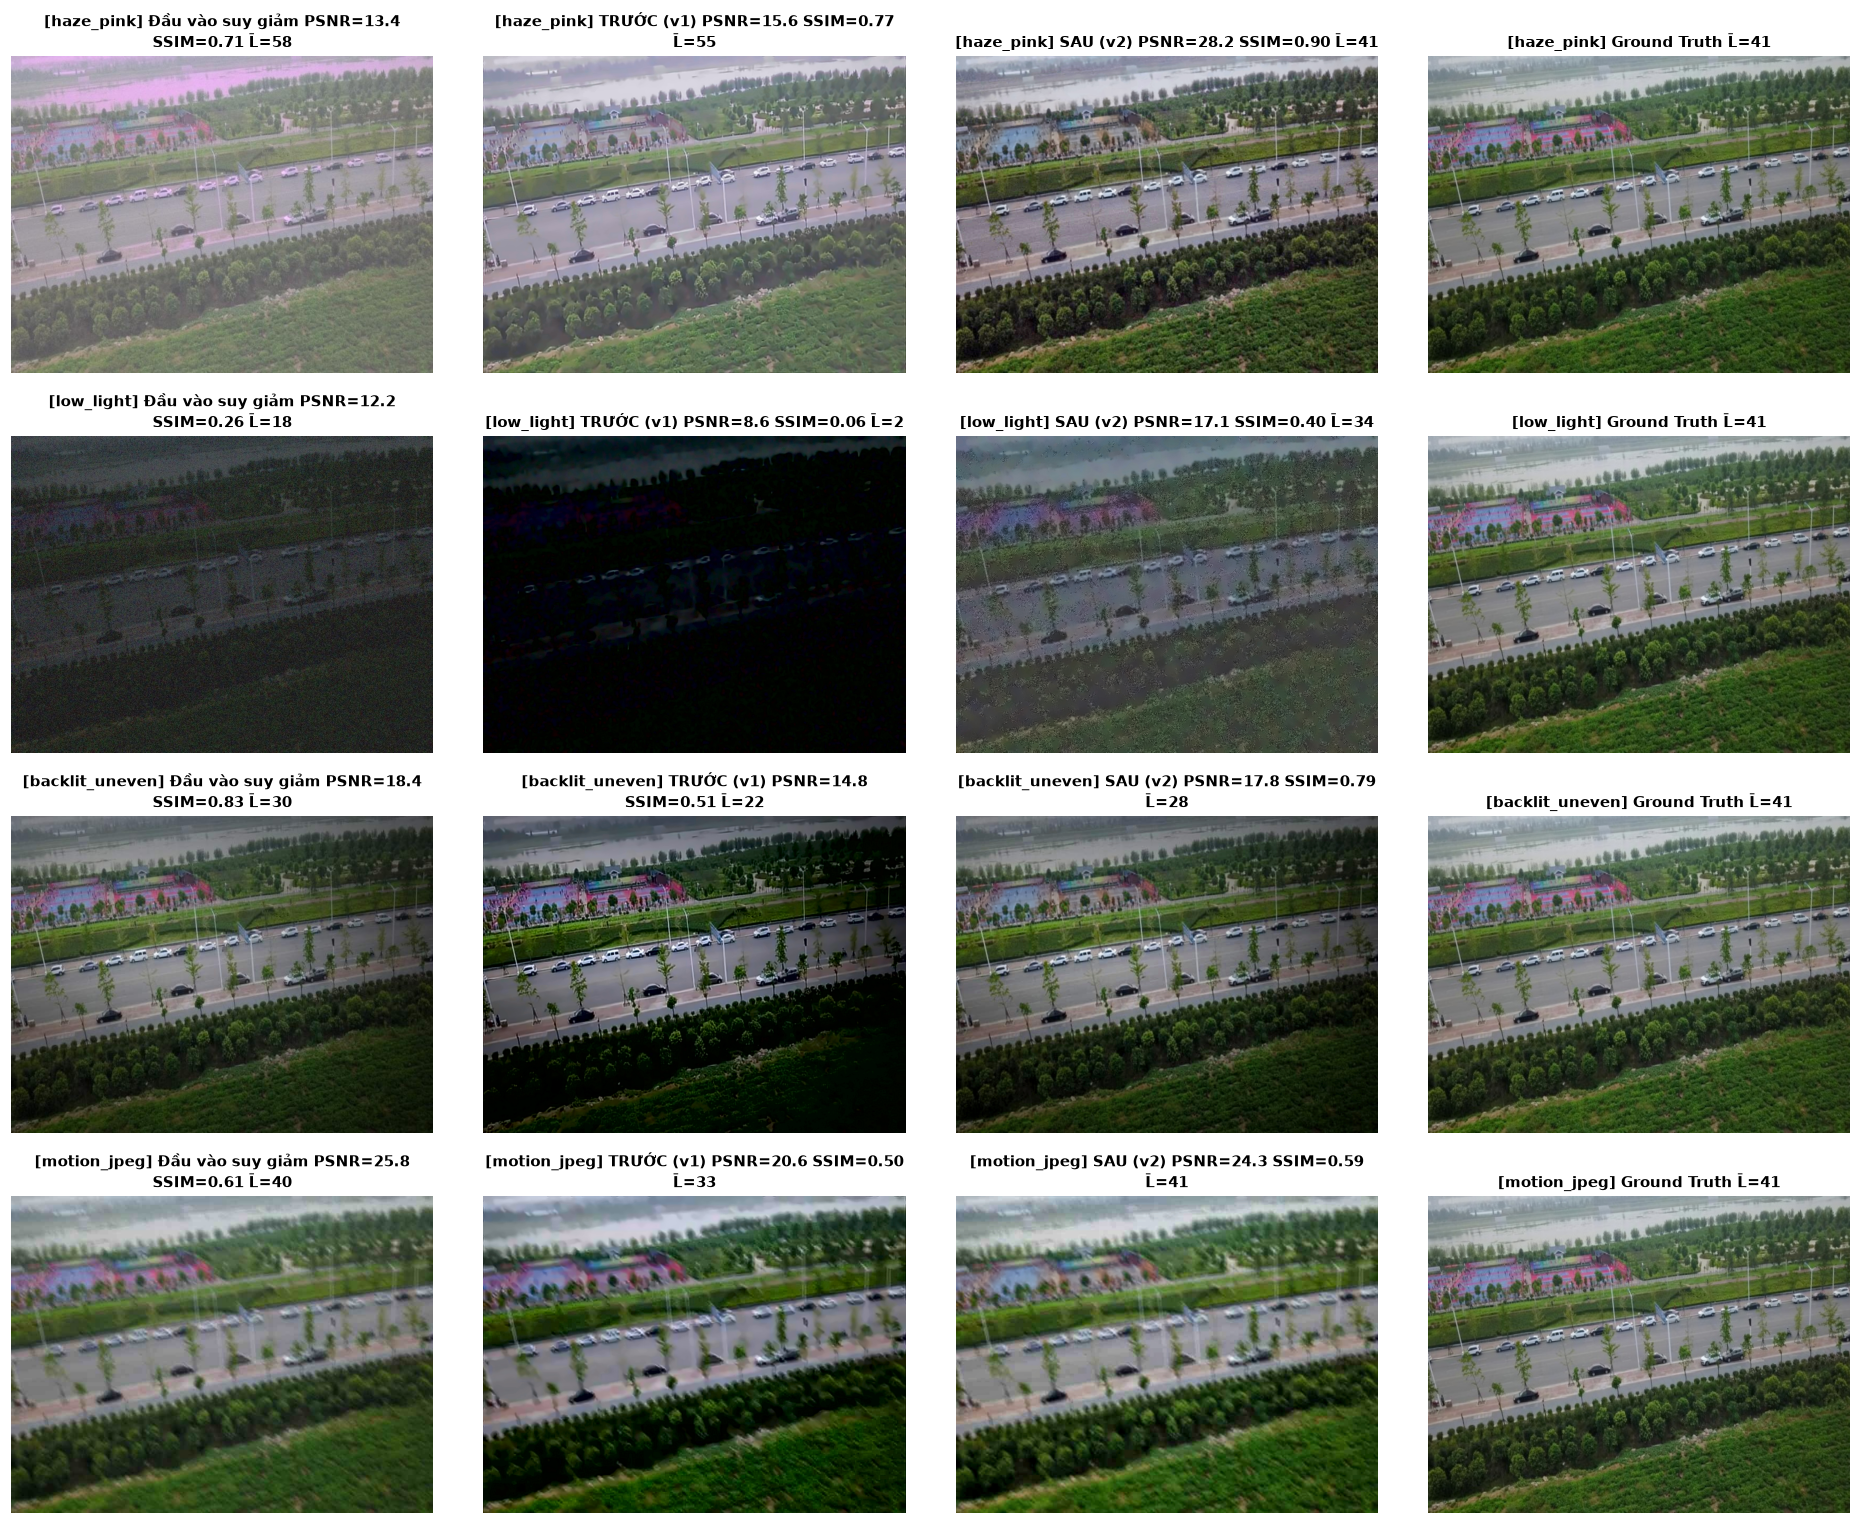

In [2]:
# xem results/figures/fig7_augmented_scenarios_before_after.png